# Setup

In [18]:
from langchain_openai import AzureChatOpenAI
import random
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage, SystemMessage
from IPython.display import Image, display
from dotenv import load_dotenv
import os

load_dotenv()

model_name = os.getenv("MODEL_NAME")

if not model_name:
    raise ValueError("Please set the MODEL_NAME environment variable.")

llm = AzureChatOpenAI(
    azure_deployment=model_name,
    api_version="2024-12-01-preview",
    temperature=0.0,
)

# Data Processing (Sequential)

In [2]:
class State(TypedDict):
    input: int
    output: int


In [3]:
def node_a(state: State)->State:
    input_value = state['input']
    offset = random.randint(1,10)
    output =  input_value + offset
    print(
        f"NODE A:\n "
        f"->input:{input_value}\n " 
        f"->offset:{offset}\n "
        f"->output:{output}\n "
    )
    return State(output=output)

In [4]:
def node_b(state: State):
    input_value = state['output']
    offset = random.randint(1,10)
    output =  input_value + offset
    print(
        f"NODE B:\n "
        f"->input:{input_value}\n " 
        f"->offset:{offset}\n "
        f"->output:{output}\n "
    )
    return {"output": output}

In [5]:
workflow = StateGraph(state_schema=State)

In [6]:
workflow.add_node(node_a)
workflow.add_node(node_b)

In [7]:
workflow.add_edge(START, "node_a")
workflow.add_edge("node_a", "node_b")
workflow.add_edge("node_b", END)

In [8]:
graph = workflow.compile()

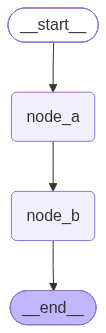

In [9]:
display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [10]:
graph.invoke(
    input = {
        "input": 1,
    }, 
)

NODE A:
 ->input:1
 ->offset:3
 ->output:4
 
NODE B:
 ->input:4
 ->offset:4
 ->output:8
 


{'input': 1, 'output': 8}

# Call LLMs

In [106]:
class State(TypedDict):
    input:str
    output:str

In [108]:
def model(state: State):
    input_value = state["input"]
    output = llm.invoke([
        SystemMessage("You're a Pokémon specialist"),
        HumanMessage(input_value)
    ])

    return {"input": input_value, "output": output.content}

In [109]:
def model_b(state: State):
    input_value = state["output"]
    output = llm.invoke([
        SystemMessage("You're a Pokémon specialist, explique bem"),
        HumanMessage(input_value)
    ])

    return {"input": input_value, "output": output.content}

In [111]:
def model_c(state: State):
    input_value = state["output"]
    output = llm.invoke([
        SystemMessage("You're a laguage specialist, translate the following text to English and french"),
        HumanMessage(input_value)
    ])

    return {"input": input_value, "output": output.content}

In [112]:
workflow = StateGraph(State)

In [113]:
workflow.add_node("model", model)
workflow.add_node("model_b", model_b)
workflow.add_node("model_c", model_c)

In [114]:
workflow.add_edge(START, "model")
workflow.add_edge("model", "model_b")
workflow.add_edge("model_b", "model_c")
workflow.add_edge("model_c", END)

In [115]:
graph = workflow.compile()

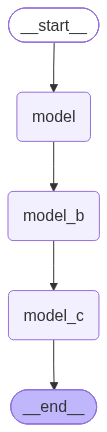

In [116]:
display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [118]:
result = graph.invoke(
    input={
        "input": "What's the name of Ash's first pokémon?"
    }, 
)

In [75]:
result

{'question': 'Sim — o primeiro Pokémon do Ash é o **Pikachu**.\n\nSó um detalhe importante: no anime, o Ash **recebe** o Pikachu do Professor Oak como seu Pokémon inicial, então ele é o primeiro Pokémon dele na jornada.',
 'response': '**English:**  \nYes — Ash’s first Pokémon is **Pikachu**.\n\nOne important detail: in the anime, Ash **receives** Pikachu from Professor Oak as his starter Pokémon, so it is the first Pokémon in his journey.\n\n**French:**  \nOui — le premier Pokémon de Sacha est **Pikachu**.\n\nUn détail important : dans l’anime, Sacha **reçoit** Pikachu du Professeur Chen comme Pokémon de départ, donc c’est le premier Pokémon de son aventure.'}